# 時間ループと最適化 ―― 虚の固定点・反復・コピーと破棄

(Version 0.2.2)

**0.2.2 での変更**: §4 に、進化計算で知られている選択の強さと多様性の釣り合い(takeover time、Goldberg & Deb 1991)との関係を書いた。地平で切り換わること自体はこの分野ではよく知られた現象の一つで、この稿で新しいのは虚実行の木との対応と、切り換わる地平の大きさの観察である。

**0.2.1 での変更**: 読み直して、§4.2 の実験の説明を 0.2.0 の実験に合わせ、§3.1 に report0 の定理 4・report2 の定理 E′ との関係を足し、§6 の表と今後の課題を report0〜report2 の現在の結果に合わせた。

**0.2.0 での変更**: 「戻らないことがある種の定常状態になる」を、両向きの定理にした。楕円型では乗数の絶対値は 1 で、実の繰り返しが元に戻るのは乗数が 1 の冪根のときに限る(定理 F′)。乗数の絶対値が 1 より小さければ、傾けても戻る(定理 F″)。リング発振器を ±1 で書いて線形の写像とし、§1 と同じ乗数(固有値)の話であることを示した(定理 R)。いずれも Lean で証明した。§4 の実験を大きくし(景観 60 個、対にした差と標準誤差)、最適なコピーの量が切り換わる地平が「独立な世界が局所的な山頂に着く時間」の約 0.4 倍であることを、山の大きさを変えて確かめた。系譜の木の大きさを Kingman の合着の式と比べた。§6 を report2 0.8.0 の結果に合わせて直した。

文責: JRF ( http://jrf.cocolog-nifty.com/ ) ／ 執筆・計算の大部分: Claude Opus 5.5 (Anthropic) ／ 2026年11月

**要旨.** JRF は 2025 年 1 月の日記で、最適化を拡張する手がかりとして、次のように書いた。

> 一般的な最適化過程というのは、むしろ定常状態からはじまり、ある方向に傾けると、反作用的な力が生じると想定する。その辺で微分と反作用が何か一般的な機構としてありうる。
>
> そして、定常状態に戻らない場合、しかし、多くのものは定常状態的に戻る中で、戻らないことがある種の定常状態になる。これが、メタ的な・または外部接続的な微分と反作用概念になるのではないか?
>
> (callCC の goto と ELDE の記事を挙げて)ただ、最適化にそれをどうつなげればいいのかはまだぜんぜんわからない。

この稿は、この問いに虚実行の側から答えようとする。

1. **「戻らないことがある種の定常状態になる」には、正確な形がある.** 繰り返し $x \leftarrow f(x)$ の定常状態は $f$ の不動点で、そこでの微分(乗数)が「傾けたときの反作用」の強さである。乗数の絶対値が 1 より小さければ傾けても戻り、大きければ離れていく。絶対値がちょうど 1 で 1 でないとき、実数の範囲では決して定常状態に戻らず回り続ける。そのときの定常状態は **虚数の不動点** にあり、そこでの微分の偏角が回る速さを与える。report0 の時間ループ(自分の未来の出力を読む実行)の解 $x=\pm i$ はこれで、$f'(i) = e^{2i\theta}$ が実実行の回転の角度を与える。メビウス変換について、乗数・標準形・周期を Lean で証明する(**定理 F・G**、§1)。さらに、実の繰り返しが元に戻るのは乗数が 1 の冪根のときに限り(**定理 F′**)、乗数の絶対値が 1 より小さければ傾けても戻る(**定理 F″**)。
2. 同じ形は、線形の力学系の複素固有値と、電子回路の **発振条件**(バルクハウゼン条件)にある。否定を輪につないだ **リング発振器** は、嘘つきの文の時間ループを回路にしたもので、自己無撞着な値を持たない代わりに周期 $2N$ で発振する。状態を ±1 で書けばこれは線形の写像で、その乗数(固有値)はどれも絶対値 1 で 1 にならない(**定理 R**、§2)。
3. 時間ループを「自分の未来を読む」でなく「同じ過去に何度も戻る」として実行すると、callCC の goto ループになる。自己無撞着な状態は、そこでは **同じ値で過去に戻り続ける、終わらない世界** として現れる。JRF の callCC の例で "stop" が無限ループになったのはこれである(§3)。
4. 遺伝的アルゴリズムの選択、粒子フィルタのリサンプリング、ビームサーチは、どれも世界(個体・粒子・候補)を **コピーし、捨てる** 探索で、虚実行の木を育てて最後に一本の実の道を選ぶ過程と見られる。コピーの確率 $x$(report0 の母関数の $x$ にあたる)を変えて探索性能を測ると、**最適な $x$ は探索の時間の長さによって切り換わる**。短い時間ではコピーを多く許すほどよく、長い時間ではコピーしない方がよい。切り換わる地平は、独立な世界が局所的な山頂に着くまでの時間の約 0.4 倍だった(§4)。
5. これらを、JRF の「システムや主体がどんどん切り換わる最適化」という問いにつなぐ(§5)。最後に、report0〜report3 の全体をまとめる(§6)。

計算はすべてこのノートの中で再現できる(数分かかる)。定理 F・F′・F″・G・R は Lean 4(Mathlib)で証明し、ノートの最後でまとめて検査する。定理の番号は、report0 の 1〜4、report1 の A・B、report2 の C〜K に続けて F・G・R とする。

## 目次

- §0 問い ―― 微分と反作用、戻らない定常状態
- §1 不動点と反作用 ―― 乗数・標準形・周期(定理 F・G)
- §2 線形の振動・発振条件・リング発振器
- §3 同じ過去に何度も戻る ―― callCC の goto ループ
- §4 コピーと破棄による探索 ―― 虚実行の木を育てて一本の実の道を選ぶ
- §5 JRF の問いへ ―― 主体が切り換わる最適化
- §6 まとめ ―― report0〜report3 を通して
- 参考文献
- 付録 Lean による一括検証

## §0 問い ―― 微分と反作用、戻らない定常状態

report0 §10.4 で、状態 $x$ を角度 $\theta$ だけ回す CS

$$ f_\theta(x) = \frac{x + \tan\theta}{1 - x\tan\theta} $$

を考えた。実実行(CS を順に繰り返す)では、$x = \tan\alpha$ は $\tan(\alpha + k\theta)$ と実数の中で回り続ける。CS が自分の出力を読む時間ループ $x = f_\theta(x)$ にすると、自己無撞着な状態は $x = \pm i$ しかない。report0 0.3 では、その時間ループが ELDE の再生では「実行」できず、候補が一周して戻るかを検査できるだけであることを見た(自己無撞着なものだけが存在する)。

この稿の問いは、その虚数の解が、実実行について何を教えてくれるかである。答えの要点は、**虚数の不動点での微分が、実実行の振る舞い(回る速さ・周期)を決める** ことにある。これは JRF の言う「微分と反作用」「戻らないことがある種の定常状態になる」に、正確な意味を与える。

In [1]:
import matplotlib
import matplotlib.pyplot as plt
try:
    import japanize_matplotlib  # noqa: F401
except Exception:
    from matplotlib import font_manager
    for name in ["Noto Sans CJK JP", "IPAexGothic", "IPAGothic", "TakaoGothic", "Yu Gothic", "Meiryo"]:
        if any(name == f.name for f in font_manager.fontManager.ttflist):
            matplotlib.rcParams["font.family"] = name
            break
matplotlib.rcParams["axes.unicode_minus"] = False
import numpy as np
import cmath, math, statistics, time
print("ok")

ok


#### `kj_loop.py`

メビウス変換 `mob`・`fixed_points`・`multiplier`・`classify`、リング発振器 `ring_oscillator`、再実行による callCC `run_with_callcc`、NK 景観 `NK` とコピーと破棄の探索 `copy_discard_search`。

In [2]:
%%writefile kj_loop.py
# -*- coding: utf-8 -*-
"""kj_loop.py -- 「時間ループと最適化」(report3)の計算コア。

* メビウス変換の反復と不動点の分類(乗数 = 不動点での微分)
* リング発振器(否定を輪にした回路) = 嘘つきの時間ループの物理的な実現
* 再実行による callCC の goto ループ(同じ過去に何度も戻る反復)
* コピーと破棄による探索(GA の選択・粒子フィルタのリサンプリング・ビームサーチの共通の形)
"""
from __future__ import annotations
import cmath
import math
import random


Overwriting kj_loop.py


In [3]:
%%writefile -a kj_loop.py
# ------------------------------------------------------------------
# メビウス変換


Appending to kj_loop.py


In [4]:
%%writefile -a kj_loop.py
# ------------------------------------------------------------------
def mob(M, x):
    a, b, c, d = M
    den = c * x + d
    return math.inf if den == 0 else (a * x + b) / den


def fixed_points(M):
    """c z^2 + (d - a) z - b = 0 の解(c = 0 なら一つ)。"""
    a, b, c, d = M
    if c == 0:
        return [b / (d - a)] if d != a else []
    disc = cmath.sqrt((d - a) ** 2 + 4 * b * c)
    return [((a - d) + disc) / (2 * c), ((a - d) - disc) / (2 * c)]


def multiplier(M, z):
    """不動点 z での微分(乗数) f'(z) = (ad - bc)/(cz + d)^2。"""
    a, b, c, d = M
    return (a * d - b * c) / (c * z + d) ** 2


def classify(M):
    """行列式で正規化したトレースで分類する(実係数、行列式 > 0)。"""
    a, b, c, d = M
    det = a * d - b * c
    tr = (a + d) / math.sqrt(det)
    if abs(tr) < 2 - 1e-12:
        return "楕円型(回転)"
    if abs(abs(tr) - 2) <= 1e-12:
        return "放物型"
    return "双曲型(収束)"


def orbit(M, x0, n):
    xs = [x0]
    for _ in range(n):
        xs.append(mob(M, xs[-1]))
    return xs


Appending to kj_loop.py


In [5]:
%%writefile -a kj_loop.py
# ------------------------------------------------------------------
# リング発振器: N 個の否定(インバータ)を輪につなぎ、各段は 1 時刻遅れて前段の否定を出す


Appending to kj_loop.py


In [6]:
%%writefile -a kj_loop.py
# ------------------------------------------------------------------
def ring_oscillator(N, T, init=None):
    x = list(init) if init else [0] * N
    hist = [tuple(x)]
    for _ in range(T):
        x = [1 - x[k - 1] for k in range(N)]
        hist.append(tuple(x))
    return hist


def period_of(seq):
    """列が最後に繰り返す周期(過渡部分を除く)。"""
    last = {}
    for t, v in enumerate(seq):
        if v in last:
            return t - last[v]
        last[v] = t
    return None


Appending to kj_loop.py


In [7]:
%%writefile -a kj_loop.py
# ------------------------------------------------------------------
# 再実行による callCC(report2 と同じ仕組み)


Appending to kj_loop.py


In [8]:
%%writefile -a kj_loop.py
# ------------------------------------------------------------------
class _Jump(Exception):
    pass


def run_with_callcc(program, max_worlds=50):
    """プログラムを最初から再実行して、何度でも再開できる継続を実現する。

    yield ("callcc",) で ("right", k) を受け取り、yield ("throw", k, v) で callcc の時点へ
    値 v を持って戻る(その時点で ("left", v) を受け取ったかのように再実行する)。
    返り値: (世界の列 [(記録, 結果)], 打ち切ったか)
    """
    answers = {}
    worlds = []
    for _ in range(max_worlds):
        g = program()
        log, n_callcc = [], 0
        try:
            req = next(g)
            while True:
                if req[0] == "callcc":
                    k = n_callcc; n_callcc += 1
                    req = g.send(answers.get(k, ("right", k)))
                elif req[0] == "throw":
                    _, k, v = req
                    log.append(v)
                    answers = {kk: vv for kk, vv in answers.items() if kk < k}
                    answers[k] = ("left", v)
                    raise _Jump()
                elif req[0] == "log":
                    log.append(req[1]); req = next(g)
        except StopIteration as e:
            worlds.append((log, e.value))
            return worlds, False
        except _Jump:
            worlds.append((log, None))
    return worlds, True


Appending to kj_loop.py


In [9]:
%%writefile -a kj_loop.py
# ------------------------------------------------------------------
# コピーと破棄による探索
#   NK 景観(Kauffman): N ビットの列、各ビットの寄与は自分と K 個の隣のビットで決まる乱数表。
#   世界(個体・粒子)を pop 個持ち、各時刻:
#     1. 各世界は 1 ビットを変えてみて、悪くならなければ受け入れる(各世界の中では実実行)。
#     2. 各世界は確率 x で、二つを選んで良い方の **コピー** に置き換わる(自分の系統は捨てられる)。
#   x = 0 は独立な山登り(コピーなし)、x = 1 は毎回全員が選択される強い選択。


Appending to kj_loop.py


In [10]:
%%writefile -a kj_loop.py
# ------------------------------------------------------------------
class NK:
    def __init__(self, N, K, seed):
        rng = random.Random(seed)
        self.N, self.K = N, K
        self.nb = [[i] + rng.sample([j for j in range(N) if j != i], K) for i in range(N)]
        self.tab = [[rng.random() for _ in range(2 ** (K + 1))] for _ in range(N)]

    def fitness(self, s):
        tot = 0.0
        for i in range(self.N):
            idx = 0
            for j in self.nb[i]:
                idx = idx * 2 + s[j]
            tot += self.tab[i][idx]
        return tot / self.N


def copy_discard_search(land, pop, T, x, seed):
    """返り値: (最良の適応度, 世代ごとの系統(祖先の番号)の記録, コピーの回数)。

    x は数か、時刻 t(0..T-1)を受け取ってコピーの確率を返す関数(切り換えの予定表)。"""
    rng = random.Random(seed)
    N = land.N
    worlds = [[rng.randrange(2) for _ in range(N)] for _ in range(pop)]
    fit = [land.fitness(w) for w in worlds]
    parent_hist = []           # 各時刻、世界 i がどの世界のコピーか(コピーでなければ自分)
    copies = 0
    for t in range(T):
        for i in range(pop):
            j = rng.randrange(N)
            w = worlds[i][:]
            w[j] ^= 1
            f = land.fitness(w)
            if f >= fit[i]:
                worlds[i], fit[i] = w, f
        par = list(range(pop))
        new_w, new_f = worlds[:], fit[:]
        xt = x(t) if callable(x) else x
        for i in range(pop):
            if rng.random() < xt:
                a, b = rng.randrange(pop), rng.randrange(pop)
                src = a if fit[a] >= fit[b] else b
                if src != i:
                    new_w[i], new_f[i] = worlds[src][:], fit[src]
                    par[i] = src
                    copies += 1
        worlds, fit = new_w, new_f
        parent_hist.append(par)
    return max(fit), parent_hist, copies


def surviving_lineages(parent_hist, pop):
    """最後の世界たちの祖先をたどり、各時刻に生き残っている系統の数を返す。"""
    alive = set(range(pop))
    counts = [len(alive)]
    for par in reversed(parent_hist):
        alive = {par[i] for i in alive}
        counts.append(len(alive))
    return list(reversed(counts))


def climb_time(land, seed, Tmax=5000):
    """コピーなし(x = 0)の一つの世界が、どの 1 ビットの変更でも良くならない状態(局所的な山頂)に初めて着く時刻。"""
    rng = random.Random(seed)
    N = land.N
    w = [rng.randrange(2) for _ in range(N)]
    f = land.fitness(w)

    def local_opt(w, f):
        for j in range(N):
            w[j] ^= 1
            g = land.fitness(w)
            w[j] ^= 1
            if g > f:
                return False
        return True
    for t in range(Tmax):
        if t % 5 == 0 and local_opt(w, f):
            return t
        j = rng.randrange(N)
        w2 = w[:]
        w2[j] ^= 1
        g = land.fitness(w2)
        if g >= f:
            w, f = w2, g
    return Tmax


class Flat:
    """どこも同じ適応度の景観(選択の効かない中立な場合)。"""
    def __init__(self, N):
        self.N = N

    def fitness(self, s):
        return 0.0


def coalescent_lineages(K, x, t):
    """中立なコピー(確率 x、K 個の世界)で、t 時刻さかのぼったときに残る系統の数の近似(Kingman の合着)。
    二つの系統が一時刻で一つにまとまる確率は約 (2x − x²)/K。"""
    p = (2 * x - x * x) / K
    return 1.0 / (1.0 - (1.0 - 1.0 / K) * math.exp(-p * t / 2.0))


Appending to kj_loop.py


In [11]:
from kj_loop import *
print('ok')

ok


## §1 不動点と反作用 ―― 乗数・標準形・周期

### 1.1 乗数は「傾けたときの反作用」

繰り返し $x_{k+1} = f(x_k)$ の定常状態は、$f$ の不動点 $z$($f(z) = z$)である。$z$ から少しずらして $x = z + \varepsilon$ とすると、

$$ f(z + \varepsilon) \approx z + f'(z)\,\varepsilon $$

なので、ずれは一回ごとに $\lambda = f'(z)$ 倍になる。この $\lambda$ を不動点の **乗数** という。

- $|\lambda| < 1$: 傾けても戻る(引き寄せる不動点)。反作用が働く定常状態。
- $|\lambda| > 1$: 傾けると離れていく(突き放す不動点)。
- $|\lambda| = 1$, $\lambda \ne 1$: 戻りも離れもせず、**回り続ける**(中立な不動点)。$\lambda = e^{i\varphi}$ なら一回ごとに角度 $\varphi$ だけ回る。

JRF の「ある方向に傾けると、反作用的な力が生じる」「微分と反作用」は、乗数そのものである。

### 1.2 メビウス変換

$f(x) = (ax+b)/(cx+d)$(実係数、$ad - bc > 0$)は、二つの不動点を持つ(重なることもある)。行列式で正規化したトレース $\tau = (a+d)/\sqrt{ad-bc}$ で、次の三つに分かれる(Needham 1997)。

| 型 | $\tau$ | 不動点 | 乗数 | 実数の繰り返し |
|---|---|---|---|---|
| 双曲型 | $|\tau| > 2$ | 実数が二つ | 一方は $|\lambda|<1$、他方は $1/\lambda$ | 引き寄せる不動点に収束する(定常状態に戻る) |
| 放物型 | $|\tau| = 2$ | 実数が一つ(重根) | $\lambda = 1$ | ゆっくり不動点に近づく |
| 楕円型 | $|\tau| < 2$ | 共役な虚数が二つ | $|\lambda| = 1$ | **決して収束せず回り続ける** |

**楕円型では、実数の範囲に定常状態がない。** 実実行は戻らずに回り続け、その「定常状態」は虚数の不動点にある。そしてそこでの乗数 $e^{i\varphi}$ が、回る角度 $\varphi$ を与える。JRF の「戻らないことがある種の定常状態になる」は、楕円型の不動点のことだと言える。

双曲型 (x+1)/(0.5x+1): 双曲型(収束)  不動点 ['1.414+0.000j', '-1.414-0.000j']  乗数 ['0.172-0.000j', '5.828-0.000j']  |乗数| [0.172, 5.828]
放物型 2 - 1/x: 放物型  不動点 ['1.000+0.000j', '1.000-0.000j']  乗数 ['1.000-0.000j', '1.000-0.000j']  |乗数| [1.0, 1.0]
楕円型 回転 θ=0.7: 楕円型(回転)  不動点 ['-0.000-1.000j', '-0.000+1.000j']  乗数 ['0.170-0.985j', '0.170+0.985j']  |乗数| [1.0, 1.0]


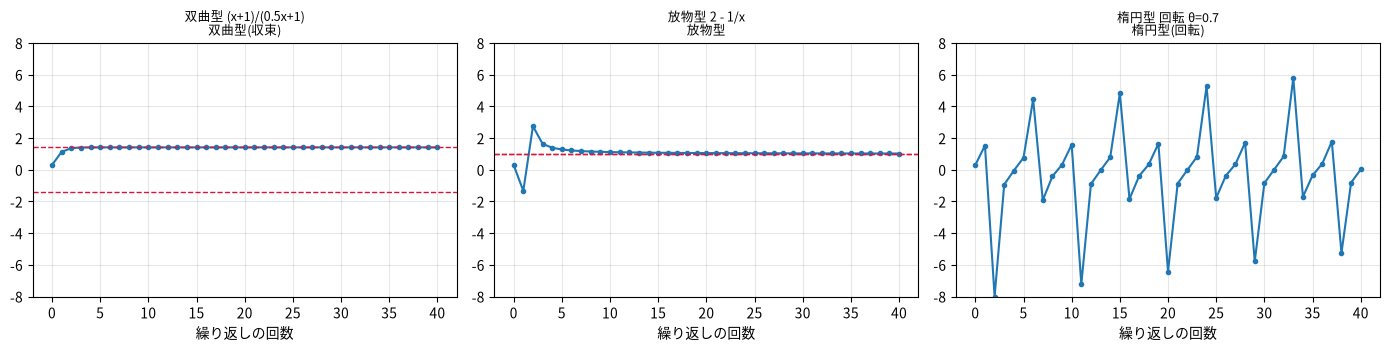

In [12]:
cases = {"双曲型 (x+1)/(0.5x+1)": (1, 1, 0.5, 1),
         "放物型 2 - 1/x": (2, -1, 1, 0),
         "楕円型 回転 θ=0.7": (math.cos(0.7), math.sin(0.7), -math.sin(0.7), math.cos(0.7))}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (name, M) in zip(axes, cases.items()):
    fps = fixed_points(M)
    print(f"{name}: {classify(M)}  不動点 {[f'{z:.3f}' for z in fps]}  乗数 {[f'{multiplier(M, z):.3f}' for z in fps]}  "
          f"|乗数| {[round(abs(multiplier(M, z)), 3) for z in fps]}")
    xs = orbit(M, 0.3, 40)
    ax.plot(range(len(xs)), np.clip(xs, -8, 8), "o-", ms=3)
    for z in fps:
        if abs(z.imag) < 1e-12:
            ax.axhline(z.real, color="crimson", ls="--", lw=1)
    ax.set_ylim(-8, 8); ax.set_title(f"{name}\n{classify(M)}", fontsize=9); ax.set_xlabel("繰り返しの回数"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

双曲型と放物型では、実数の繰り返しは赤い破線(実数の不動点)に近づく。楕円型(回転)には実数の不動点がなく、繰り返しは回り続ける。不動点は $\pm i$ で、乗数は絶対値 1 の複素数 $e^{\pm 2i\theta}$ である。

### 1.3 標準形と周期

二つの不動点 $z_1 \ne z_2$ で座標を取り直し、$R(x) = (x - z_1)/(x - z_2)$ とおくと、メビウス変換は **掛け算** になる。

$$ R(f(x)) = \lambda\, R(x), \qquad \lambda = \frac{a - c z_1}{a - c z_2} = f'(z_1). $$

したがって $n$ 回の繰り返しは $R(f^n(x)) = \lambda^n R(x)$ で、**$\lambda^n = 1$ なら $n$ 回で元に戻る**。

**定理 F(周期).** メビウス変換の二つの不動点 $z_1 \ne z_2$ について、乗数 $\lambda$ が 1 の $n$ 乗根なら、繰り返し(実実行)は $n$ 回で元の値に戻る。

**定理 G.** 回転 $f_\theta(x) = (\cos\theta\, x + \sin\theta)/(-\sin\theta\, x + \cos\theta)$($= (x + \tan\theta)/(1 - x\tan\theta)$)の時間ループの解 $x = i$ での乗数は $e^{2i\theta}$ である。

したがって、回転の実実行が何回で元に戻るかは $e^{2in\theta} = 1$、すなわち $n\theta$ が $\pi$ の整数倍になる最小の $n$ で、**時間ループの虚の解だけを見て、実実行の周期が読める**。

Lean では、メビウス変換の微分 `mob_hasDerivAt`、不動点での微分が $(a - cz)/(cz+d)$ になること `multiplier_at_fixed`、標準形 `normal_form`、繰り返し `iterate_ratio`、周期 `period`(定理 F)、回転の乗数 `rot_multiplier`(定理 G)を示す。

In [13]:
%%writefile test.lean
import Mathlib

set_option autoImplicit false

namespace ImagExec.R3

open Complex

/-! ## 1. メビウス変換の不動点と、そこでの微分(反作用の強さ)

`f x = (a x + b) / (c x + d)`。不動点 `z` は `c z² + (d − a) z − b = 0` を満たす。 -/

/-- メビウス変換。 -/
noncomputable def mob (a b c d : ℂ) (x : ℂ) : ℂ := (a * x + b) / (c * x + d)

/-- 微分: `f' x = (a d − b c) / (c x + d)²`。 -/
theorem mob_hasDerivAt (a b c d x : ℂ) (hx : c * x + d ≠ 0) :
    HasDerivAt (mob a b c d) ((a * d - b * c) / (c * x + d) ^ 2) x := by
  have h1 : HasDerivAt (fun y => a * y + b) a x := by
    simpa using ((hasDerivAt_id x).const_mul a).add_const b
  have h2 : HasDerivAt (fun y => c * y + d) c x := by
    simpa using ((hasDerivAt_id x).const_mul c).add_const d
  have := h1.div h2 hx
  convert this using 1
  · rfl
  · rw [div_eq_div_iff (pow_ne_zero 2 hx) (pow_ne_zero 2 hx)]
    ring

/-- 不動点 `z` での微分は `(a − c z)/(c z + d)` に等しい。これを不動点の **乗数** と呼ぶ。 -/
theorem multiplier_at_fixed (a b c d z : ℂ) (hz : c * z ^ 2 + (d - a) * z - b = 0)
    (hd : c * z + d ≠ 0) :
    (a * d - b * c) / (c * z + d) ^ 2 = (a - c * z) / (c * z + d) := by
  rw [div_eq_div_iff (pow_ne_zero 2 hd) hd]
  linear_combination ((c * z + d) * c) * hz

/-- 不動点 `z` からのずれは、乗数の倍率で伸び縮みする: `f x − z = (x − z)(a − c z)/(c x + d)`。 -/
theorem sub_fixed (a b c d z x : ℂ) (hz : c * z ^ 2 + (d - a) * z - b = 0)
    (hx : c * x + d ≠ 0) :
    mob a b c d x - z = (x - z) * (a - c * z) / (c * x + d) := by
  unfold mob
  rw [div_sub' hx, div_eq_div_iff hx hx]
  linear_combination (-(c * x + d)) * hz


Overwriting test.lean


In [14]:
%%writefile -a test.lean
/-! ## 2. 標準形: 二つの不動点で座標を取り直すと、メビウス変換は掛け算になる

二つの不動点 `z₁ ≠ z₂` について `R(x) = (x − z₁)/(x − z₂)` とおくと、`R(f x) = λ R(x)`、
`λ = (a − c z₁)/(a − c z₂)`。`λ` は `z₁` での乗数(微分)に等しい。 -/

/-- 二つの不動点の和(根と係数の関係): `a − c z₂ = c z₁ + d`。 -/
theorem vieta (a b c d z₁ z₂ : ℂ) (h₁ : c * z₁ ^ 2 + (d - a) * z₁ - b = 0)
    (h₂ : c * z₂ ^ 2 + (d - a) * z₂ - b = 0) (hne : z₁ ≠ z₂) : a - c * z₂ = c * z₁ + d := by
  have : (z₁ - z₂) * (c * (z₁ + z₂) + d - a) = 0 := by linear_combination h₁ - h₂
  rcases mul_eq_zero.mp this with h | h
  · exact absurd (sub_eq_zero.mp h) hne
  · linear_combination -h

theorem normal_form (a b c d z₁ z₂ x : ℂ) (h₁ : c * z₁ ^ 2 + (d - a) * z₁ - b = 0)
    (h₂ : c * z₂ ^ 2 + (d - a) * z₂ - b = 0) (hx : c * x + d ≠ 0) :
    (mob a b c d x - z₁) / (mob a b c d x - z₂) =
      (a - c * z₁) / (a - c * z₂) * ((x - z₁) / (x - z₂)) := by
  rw [sub_fixed a b c d z₁ x h₁ hx, sub_fixed a b c d z₂ x h₂ hx]
  rw [div_div_div_cancel_right₀ hx, mul_div_mul_comm, mul_comm]

/-- n 回繰り返すと乗数の n 乗: 列 `x (k+1) = f (x k)` について `R(x n) = λⁿ R(x 0)`。 -/
theorem iterate_ratio (a b c d z₁ z₂ : ℂ) (h₁ : c * z₁ ^ 2 + (d - a) * z₁ - b = 0)
    (h₂ : c * z₂ ^ 2 + (d - a) * z₂ - b = 0)
    (x : ℕ → ℂ) (hrec : ∀ k, x (k + 1) = mob a b c d (x k))
    (hden : ∀ k, c * x k + d ≠ 0) (n : ℕ) :
    (x n - z₁) / (x n - z₂) = ((a - c * z₁) / (a - c * z₂)) ^ n * ((x 0 - z₁) / (x 0 - z₂)) := by
  induction n with
  | zero => simp
  | succ n ih =>
    rw [hrec n, normal_form a b c d z₁ z₂ (x n) h₁ h₂ (hden n), ih, pow_succ]
    ring

/-- **定理 F(周期).** 乗数が 1 の n 乗根なら、実行は n 回で元に戻る。 -/
theorem period (a b c d z₁ z₂ : ℂ) (h₁ : c * z₁ ^ 2 + (d - a) * z₁ - b = 0)
    (h₂ : c * z₂ ^ 2 + (d - a) * z₂ - b = 0) (hne : z₁ ≠ z₂)
    (x : ℕ → ℂ) (hrec : ∀ k, x (k + 1) = mob a b c d (x k))
    (hden : ∀ k, c * x k + d ≠ 0) (hnz : ∀ k, x k ≠ z₂) (n : ℕ)
    (hn : ((a - c * z₁) / (a - c * z₂)) ^ n = 1) : x n = x 0 := by
  have h := iterate_ratio a b c d z₁ z₂ h₁ h₂ x hrec hden n
  rw [hn, one_mul] at h
  have e1 : x n - z₂ ≠ 0 := sub_ne_zero.mpr (hnz n)
  have e0 : x 0 - z₂ ≠ 0 := sub_ne_zero.mpr (hnz 0)
  rw [div_eq_div_iff e1 e0] at h
  have hz : z₁ - z₂ ≠ 0 := sub_ne_zero.mpr hne
  have : (x n - x 0) * (z₁ - z₂) = 0 := by linear_combination h
  rcases mul_eq_zero.mp this with h' | h'
  · exact sub_eq_zero.mp h'
  · exact absurd h' hz


Appending to test.lean


In [15]:
%%writefile -a test.lean
/-! ## 3. 回転: 時間ループの解 ±i と、そこでの微分 e^{2iθ}

角度 θ の回転 `x ↦ (cos θ · x + sin θ)/(−sin θ · x + cos θ)`(= `(x + tan θ)/(1 − x tan θ)`)。
不動点は `±i` で、`i` での乗数は `e^{2iθ}`。 -/

theorem rot_fixed (θ : ℂ) (z : ℂ) (hz : z = I ∨ z = -I) :
    (-sin θ) * z ^ 2 + (cos θ - cos θ) * z - sin θ = 0 := by
  rcases hz with rfl | rfl <;> simp [sq]

/-- **定理 G.** 回転の時間ループの解 `i` での微分(乗数)は `e^{2iθ}`。 -/
theorem rot_multiplier (θ : ℂ) (h : cos θ - sin θ * I ≠ 0) :
    (cos θ - (-sin θ) * I) / ((-sin θ) * I + cos θ) = exp (2 * θ * I) := by
  have hc : (cos θ - sin θ * I) * (cos θ + sin θ * I) = 1 := by
    have := cos_sq_add_sin_sq θ
    linear_combination this - (sin θ) ^ 2 * (I_sq)
  have e : exp (2 * θ * I) = (cos θ + sin θ * I) ^ 2 := by
    rw [show 2 * θ * I = θ * I + θ * I by ring, exp_add, exp_mul_I, sq]
  rw [e, show (-sin θ) * I + cos θ = cos θ - sin θ * I by ring, div_eq_iff h]
  linear_combination (-(cos θ + sin θ * I)) * hc


Appending to test.lean


In [16]:
for n in [3, 4, 6, 7]:
    th = math.pi / n
    M = (math.cos(th), math.sin(th), -math.sin(th), math.cos(th))
    lam = multiplier(M, 1j)
    xs = orbit(M, 0.3, 2 * n)
    back = next(k for k in range(1, 2 * n + 1) if abs(xs[k] - xs[0]) < 1e-9)
    print(f"θ = π/{n}: 乗数 f'(i) = {lam:.4f} = e^(2iθ) = {cmath.exp(2j * th):.4f},  λ^{n} = {lam ** n:.4f},  実実行が戻るまで {back} 回")

θ = π/3: 乗数 f'(i) = -0.5000+0.8660j = e^(2iθ) = -0.5000+0.8660j,  λ^3 = 1.0000-0.0000j,  実実行が戻るまで 3 回
θ = π/4: 乗数 f'(i) = 0.0000+1.0000j = e^(2iθ) = 0.0000+1.0000j,  λ^4 = 1.0000-0.0000j,  実実行が戻るまで 4 回
θ = π/6: 乗数 f'(i) = 0.5000+0.8660j = e^(2iθ) = 0.5000+0.8660j,  λ^6 = 1.0000-0.0000j,  実実行が戻るまで 6 回
θ = π/7: 乗数 f'(i) = 0.6235+0.7818j = e^(2iθ) = 0.6235+0.7818j,  λ^7 = 1.0000-0.0000j,  実実行が戻るまで 7 回


### 1.4 戻るのは 1 の冪根のときだけ ―― 定理 F′・F″

定理 F は「乗数が 1 の冪根なら戻る」だけを言っていた。楕円型については、逆も言える。

**定理 F′(楕円型).** 係数が実数のメビウス変換が実数でない不動点 $z$ を持つとき(楕円型)、もう一つの不動点は共役 $\bar z$ で、

1. 乗数 $\lambda = (a - cz)/(a - c\bar z)$ の絶対値は 1 である。
2. 座標 $R(x) = (x - z)/(x - \bar z)$ は実数直線を単位円に移し、実の繰り返しは単位円の上で角度 $\arg\lambda$ ずつの回転になる。
3. 実の繰り返しが $n$ 回で元の値に戻るのは、$\lambda^n = 1$ のとき **に限る**。したがって $\lambda$ が 1 の冪根でなければ($\arg\lambda / 2\pi$ が無理数なら)、実の繰り返しは **決して元の値に戻らない**。

**証明.** 1: $a - c\bar z$ は $a - cz$ の共役なので、二つの絶対値は等しい($a - cz \ne 0$ は $z$ が実数でないことから)。2: 実数 $x$ について $x - \bar z$ は $x - z$ の共役なので $|R(x)| = 1$。標準形 $R(f(x)) = \lambda R(x)$ と合わせればよい。3: $R(x_n) = \lambda^n R(x_0)$ で、$x_n = x_0$ なら $R(x_0) \ne 0$(単位円上)で割って $\lambda^n = 1$。逆は定理 F。∎

**定理 F″(傾けても戻る).** 二つの不動点 $z_1 \ne z_2$ について $|f'(z_1)| = |\lambda| < 1$ なら、$z_2$ を通らない繰り返しは $z_1$ に収束する。

**証明.** $R(x_n) = \lambda^n R(x_0) \to 0$。$x_n$ を $R(x_n)$ で解くと $x_n = (z_1 - R(x_n) z_2)/(1 - R(x_n))$ で、これは $z_1$ に近づく。∎

こうして、JRF の二つの言葉に両向きの定理が対応する。「**傾けると反作用が生じて戻る**」は $|f'(z)| < 1$ のときの収束(定理 F″)、「**戻らないことがある種の定常状態になる**」は楕円型で、実の繰り返しは虚数の不動点のまわりの回転として **ちょうど** 記述され、回転の角度が 1 の冪根に当たらなければ決して戻らない(定理 F′)。Lean では `elliptic_unit`・`real_to_circle`・`elliptic_return`(定理 F′)、`converge`(定理 F″)として証明した。

In [17]:
%%writefile -a test.lean
/-! ## 4. 楕円型: 実の繰り返しは単位円上の回転で、乗数が 1 の冪根のときに限って戻る

係数が実数で、不動点 `z` が実数でない(楕円型)とき、もう一つの不動点は共役 `conj z` で、
乗数 `λ = (a − c z)/(a − c conj z)` の絶対値は 1。座標 `R(x) = (x − z)/(x − conj z)` は実数直線を単位円に移し、
実の繰り返しは単位円上の角度 `arg λ` の回転になる。実の繰り返しが元に戻るのは `λⁿ = 1` のときに限る。 -/

theorem conj_fixed (a b c d : ℝ) (z : ℂ) (hz : (c : ℂ) * z ^ 2 + ((d : ℂ) - a) * z - b = 0) :
    (c : ℂ) * (starRingEnd ℂ z) ^ 2 + ((d : ℂ) - a) * starRingEnd ℂ z - b = 0 := by
  have := congrArg (starRingEnd ℂ) hz
  simpa [map_sub, map_add, map_mul, map_pow, Complex.conj_ofReal] using this

theorem conj_ne (z : ℂ) (hzi : z.im ≠ 0) : z ≠ starRingEnd ℂ z := by
  intro h
  apply hzi
  have := congrArg Complex.im h
  simp at this
  linarith

/-- 実数 `x` について `|x − z| = |x − conj z|`。よって `R` は実数直線を単位円に移す。 -/
theorem real_to_circle (x : ℝ) (z : ℂ) (hzi : z.im ≠ 0) :
    ‖((x : ℂ) - z) / ((x : ℂ) - starRingEnd ℂ z)‖ = 1 := by
  have hne : (x : ℂ) - starRingEnd ℂ z ≠ 0 := by
    intro h
    apply hzi
    have := congrArg Complex.im h
    simp at this
    linarith
  rw [norm_div, div_eq_one_iff_eq (norm_ne_zero_iff.mpr hne)]
  have : (x : ℂ) - starRingEnd ℂ z = starRingEnd ℂ ((x : ℂ) - z) := by simp
  rw [this, Complex.norm_conj]

/-- **楕円型の乗数は絶対値 1.** -/
theorem elliptic_unit (a c : ℝ) (z : ℂ) (hc : c ≠ 0) (hzi : z.im ≠ 0) :
    ‖((a : ℂ) - c * z) / ((a : ℂ) - c * starRingEnd ℂ z)‖ = 1 := by
  have hw : (a : ℂ) - c * z ≠ 0 := by
    intro h
    apply hzi
    have := congrArg Complex.im h
    simp at this
    rcases this with h1 | h1
    · exact absurd h1 hc
    · exact h1
  have : (a : ℂ) - c * starRingEnd ℂ z = starRingEnd ℂ ((a : ℂ) - c * z) := by simp
  rw [this, norm_div, Complex.norm_conj, div_self (norm_ne_zero_iff.mpr hw)]

/-- **定理 F′(戻るのは乗数が 1 の冪根のときに限る).** 楕円型のメビウス変換の実の繰り返しについて、
`n` 回で元の値に戻る ⇔ 乗数の `n` 乗が 1。乗数が 1 の冪根でなければ、実の繰り返しは決して元の値に戻らない。 -/
theorem elliptic_return (a b c d : ℝ) (z : ℂ) (hz : (c : ℂ) * z ^ 2 + ((d : ℂ) - a) * z - b = 0)
    (hzi : z.im ≠ 0) (x : ℕ → ℝ) (hrec : ∀ k, ((x (k + 1) : ℝ) : ℂ) = mob a b c d (x k))
    (hden : ∀ k, (c : ℂ) * x k + d ≠ 0) (n : ℕ) :
    x n = x 0 ↔ (((a : ℂ) - c * z) / ((a : ℂ) - c * starRingEnd ℂ z)) ^ n = 1 := by
  have h2 := conj_fixed a b c d z hz
  have hne := conj_ne z hzi
  have hnz : ∀ k, ((x k : ℝ) : ℂ) ≠ starRingEnd ℂ z := by
    intro k h
    apply hzi
    have := congrArg Complex.im h
    simp at this
    linarith
  have hit := iterate_ratio a b c d z (starRingEnd ℂ z) hz h2 (fun k => (x k : ℂ)) hrec hden n
  constructor
  · intro hx
    rw [hx] at hit
    have hR : ((x 0 : ℂ) - z) / ((x 0 : ℂ) - starRingEnd ℂ z) ≠ 0 := by
      intro h0
      have := real_to_circle (x 0) z hzi
      rw [h0, norm_zero] at this
      exact zero_ne_one this
    have := hit.symm
    rw [mul_eq_right₀ hR] at this
    exact this
  · intro hl
    exact_mod_cast period a b c d z (starRingEnd ℂ z) hz h2 hne (fun k => (x k : ℂ)) hrec hden hnz n hl


Appending to test.lean


In [18]:
%%writefile -a test.lean
/-! ## 5. 双曲型: 乗数の絶対値が 1 より小さければ、傾けても戻る

二つの不動点 `z₁ ≠ z₂` の乗数 `λ` が `|λ| < 1` なら、`z₂` を通らない繰り返しは `z₁` に収束する
(「ある方向に傾けると、反作用的な力が生じる」の正確な形)。 -/

theorem converge (a b c d z₁ z₂ : ℂ) (h₁ : c * z₁ ^ 2 + (d - a) * z₁ - b = 0)
    (h₂ : c * z₂ ^ 2 + (d - a) * z₂ - b = 0) (hne : z₁ ≠ z₂)
    (x : ℕ → ℂ) (hrec : ∀ k, x (k + 1) = mob a b c d (x k))
    (hden : ∀ k, c * x k + d ≠ 0) (hnz : ∀ k, x k ≠ z₂)
    (hl : ‖(a - c * z₁) / (a - c * z₂)‖ < 1) :
    Filter.Tendsto x Filter.atTop (nhds z₁) := by
  set lam := (a - c * z₁) / (a - c * z₂)
  set R0 := (x 0 - z₁) / (x 0 - z₂)
  have hR : ∀ n, (x n - z₁) / (x n - z₂) = lam ^ n * R0 :=
    iterate_ratio a b c d z₁ z₂ h₁ h₂ x hrec hden
  -- x n = (z₁ − r z₂)/(1 − r)、r = λⁿ R0
  have hx : ∀ n, x n = (z₁ - lam ^ n * R0 * z₂) / (1 - lam ^ n * R0) := by
    intro n
    have e := hR n
    have hd : x n - z₂ ≠ 0 := sub_ne_zero.mpr (hnz n)
    have h1 : 1 - lam ^ n * R0 ≠ 0 := by
      rw [← e]
      intro h
      apply hne
      have : (x n - z₁) / (x n - z₂) = 1 := by linear_combination -h
      rw [div_eq_one_iff_eq hd] at this
      linear_combination -this
    rw [eq_div_iff h1, ← e]
    field_simp
    ring
  have hpow : Filter.Tendsto (fun n => lam ^ n * R0) Filter.atTop (nhds 0) := by
    have := tendsto_pow_atTop_nhds_zero_of_norm_lt_one hl
    simpa using this.mul_const R0
  have hlim : Filter.Tendsto (fun n => (z₁ - lam ^ n * R0 * z₂) / (1 - lam ^ n * R0))
      Filter.atTop (nhds ((z₁ - 0 * z₂) / (1 - 0))) := by
    apply Filter.Tendsto.div
    · exact tendsto_const_nhds.sub (hpow.mul_const z₂)
    · exact tendsto_const_nhds.sub hpow
    · simp
  simp only [zero_mul, sub_zero, div_one] at hlim
  exact (funext hx ▸ hlim : _)


Appending to test.lean


In [19]:
# 角度 1 ラジアン(π の有理数倍でない)の回転: 乗数は 1 の冪根でなく、実の繰り返しは戻らない
th = 1.0
M = (math.cos(th), math.sin(th), -math.sin(th), math.cos(th))
lam = multiplier(M, 1j)
xs = orbit(M, 0.3, 2000)
R = [(x - 1j) / (x + 1j) for x in xs]
print(f"乗数 λ = {lam:.6f}, |λ| = {abs(lam):.12f}, arg λ = {cmath.phase(lam):.6f}(= 2θ)")
print("R(x_k) の絶対値の範囲:", round(min(abs(r) for r in R), 12), "〜", round(max(abs(r) for r in R), 12))
print("1〜2000 回で x_0 に最も近づいた距離:", f"{min(abs(x - xs[0]) for x in xs[1:]):.2e}", "(0 にはならない)")
steps = [cmath.phase(R[k + 1] / R[k]) for k in range(5)]
print("単位円上で一回ごとに回る角度:", [round(a, 6) for a in steps])

乗数 λ = -0.416147+0.909297j, |λ| = 1.000000000000, arg λ = 2.000000(= 2θ)
R(x_k) の絶対値の範囲: 1.0 〜 1.0
1〜2000 回で x_0 に最も近づいた距離: 3.29e-05 (0 にはならない)
単位円上で一回ごとに回る角度: [2.0, 2.0, 2.0, 2.0, 2.0]


## §2 線形の振動・発振条件・リング発振器

### 2.1 線形の力学系

$x_{k+1} = A x_k$(実の行列 $A$)では、不動点は 0 で、乗数は $A$ の固有値である。固有値が実数で絶対値が 1 より小さければ 0 に戻る。固有値が複素数 $r e^{\pm i\varphi}$ なら、実の状態は角度 $\varphi$ ずつ回りながら $r$ 倍ずつ伸び縮みする。**実の振動を記述するのは、実でない固有値** である。電気回路の交流理論で、抵抗・コイル・コンデンサに複素インピーダンスを与えて組み立てるのも同じ考えで、振動 $\cos\omega t$ を虚数の不動点 $e^{i\omega t}$ の実部として扱う。

### 2.2 発振条件

増幅器の出力を入力に戻す(フィードバック)回路は、時間ループである。バルクハウゼン(1935)は、回路が一定の振幅で発振を続けるための条件として、ループを一周したときの利得 $\beta A$ が

$$ |\beta A| = 1, \qquad \arg(\beta A) = 2\pi n $$

になることを挙げた(必要条件)。これは、ループを一周して **自分自身に戻る**(自己無撞着な)複素数の解 $e^{i\omega t}$ が存在する条件、すなわち時間ループの乗数が 1 になる条件である。振幅が減っていく($|\beta A|<1$)か、増えていく($|\beta A|>1$)かは、§1 の乗数の絶対値の分類と同じである。

### 2.3 リング発振器 ―― 嘘つきの時間ループを回路にする

否定(インバータ)を奇数個 $N$ 個、輪につなぐと、回路は自己無撞着な値を持たない(各段は前段の否定なので、一周すると自分の否定に等しくならなければならない)。$N = 1$ はまさに「この文は偽である」という嘘つきの文を回路にしたものである。実際の回路は、自己無撞着な状態を持たない代わりに、各段の遅れの $2N$ 倍の周期で発振する。デジタル回路で時計(クロック)を作る基本的な方法の一つである。

各段が 1 時刻遅れて前段の否定を出すとして、一か所だけ食い違いのある状態から始めて周期を数える。

In [20]:
for N in [1, 3, 5, 7, 9]:
    hist = ring_oscillator(N, 4 * N + 4, init=[k % 2 for k in range(N)])
    print(f"インバータ {N} 個: 周期 {period_of(hist)}   最初の数時刻: {' '.join(''.join(map(str, h)) for h in hist[:6])}")

インバータ 1 個: 周期 2   最初の数時刻: 0 1 0 1 0 1
インバータ 3 個: 周期 6   最初の数時刻: 010 110 100 101 001 011
インバータ 5 個: 周期 10   最初の数時刻: 01010 11010 10010 10110 10100 10101
インバータ 7 個: 周期 14   最初の数時刻: 0101010 1101010 1001010 1011010 1010010 1010110
インバータ 9 個: 周期 18   最初の数時刻: 010101010 110101010 100101010 101101010 101001010 101011010


周期は $2N$ で、$N = 1$(嘘つき)では真・偽・真・偽と周期 2 で振動する。report0 §10.4 では、嘘つきの時間ループ $x = -1/x$ の自己無撞着な値が $i$ であり、実実行では真と偽の振動として時間の中に展開されることを見た。$x \mapsto -1/x$ は角度 $\pi/2$ の回転で、定理 G の乗数は $e^{i\pi} = -1$、つまり周期 2 である。リング発振器は、その振動を実際に作る回路である。

この周期も、§1・§2.1 と同じ乗数の話として読める。真偽を $+1, -1$ で書けば、否定は $-1$ 倍で、一時刻の写像は **線形** $s \mapsto -Cs$($C$ は段を一つずらす巡回シフト)になる。$C$ の固有値は 1 の $N$ 乗根 $\omega^j$ なので、乗数(固有値)は $-\omega^j$ で、どれも絶対値 1 である。$N$ が奇数なら $-\omega^j = 1$ となる $j$ はない。**乗数 1 がないことが、自己無撞着な状態(不動点)がないことであり、乗数がすべて 1 の $2N$ 乗根であることが、周期が $2N$ を割り切ることである。** 実際の周期は、初めの状態がどの固有値の成分を含むかで決まる(含まれる固有値の位数の最小公倍数)。

**定理 R(リング発振器).** インバータ $N$ 個($N$ 奇数)の輪では、$N$ 時刻後の状態は元の状態の否定になり(よって自己無撞着な状態はない)、$2N$ 時刻後に元に戻る。

Lean では、±1 で書いた一時刻の写像 `ringStep` について、`ring_N`・`ring_2N`・`ring_no_fixed` として証明した。

In [21]:
%%writefile -a test.lean
/-! ## 6. リング発振器: ±1 で書けば線形で、乗数(固有値)はどれも 1 でない

インバータ `N` 個(`N` 奇数)の輪。各段は 1 時刻遅れて前段の否定を出す。状態を ±1 で書けば否定は −1 倍なので、
一時刻の写像は線形 `s ↦ −C s`(`C` は巡回シフト)。`N` 時刻で全体の否定になり(自己無撞着な状態はない)、
`2N` 時刻で元に戻る。 -/

/-- 一時刻: 段 `k` は前段 `k − 1` の否定(±1 で書いて −1 倍)を出す。 -/
def ringStep (N : ℕ) (s : ZMod N → ℤ) : ZMod N → ℤ := fun k => -s (k - 1)

theorem ringStep_iter (N : ℕ) (s : ZMod N → ℤ) (m : ℕ) (k : ZMod N) :
    (ringStep N)^[m] s k = (-1) ^ m * s (k - m) := by
  induction m generalizing k with
  | zero => simp
  | succ m ih =>
    rw [Function.iterate_succ_apply', ringStep, ih]
    push_cast
    ring_nf

/-- **リング発振器(N 奇数).** `N` 時刻で全体が否定になる(自己無撞着な状態はない)。 -/
theorem ring_N (N : ℕ) (hN : Odd N) (s : ZMod N → ℤ) :
    (ringStep N)^[N] s = fun k => - s k := by
  funext k
  rw [ringStep_iter, ZMod.natCast_self, sub_zero, hN.neg_one_pow]
  ring

/-- **リング発振器.** `2N` 時刻で元に戻る。 -/
theorem ring_2N (N : ℕ) (s : ZMod N → ℤ) : (ringStep N)^[2 * N] s = s := by
  funext k
  rw [ringStep_iter]
  have : ((2 * N : ℕ) : ZMod N) = 0 := by
    rw [Nat.cast_mul, ZMod.natCast_self, mul_zero]
  rw [this, sub_zero, pow_mul]
  simp

/-- 状態がどれも 0 でない(±1 の)とき、`N` 時刻後の状態は元と違う: 輪は止まらない。 -/
theorem ring_no_fixed (N : ℕ) (hN : Odd N) (s : ZMod N → ℤ) (k : ZMod N) (hk : s k ≠ 0) :
    (ringStep N)^[N] s ≠ s := by
  intro h
  have := congrFun h k
  rw [ring_N N hN] at this
  exact hk (by linarith)

end ImagExec.R3


Appending to test.lean


In [22]:
# ±1 で書いた線形の写像 −C の固有値(乗数)と、初めの状態の成分から決まる周期
from math import gcd
def lcm(a, b): return a * b // gcd(a, b)
for N in [3, 5, 7]:
    C = np.roll(np.eye(N), 1, axis=0)                  # (Cs)_k = s_{k-1}
    A = -C
    ev = np.linalg.eigvals(A)
    for name, init in [("一か所だけ食い違い", [k % 2 for k in range(N)]), ("全部 0", [0] * N)]:
        s = np.array([1 - 2 * b for b in init], dtype=float)
        V = np.linalg.eig(A)[1]
        coef = np.linalg.solve(V, s)
        orders = [next(m for m in range(1, 4 * N + 1) if abs(e ** m - 1) < 1e-9) for e, c in zip(ev, coef) if abs(c) > 1e-9]
        pred = 1
        for o in orders: pred = lcm(pred, o)
        sim = period_of(ring_oscillator(N, 4 * N + 4, init=init))
        print(f"N={N} {name}: 乗数の絶対値 {sorted(set(float(v) for v in np.round(abs(ev), 9)))}, 乗数 1 があるか {any(abs(e - 1) < 1e-9 for e in ev)}, "
              f"成分を持つ乗数の位数 {sorted(set(orders))} → 予測周期 {pred}, シミュレーション {sim}")

N=3 一か所だけ食い違い: 乗数の絶対値 [1.0], 乗数 1 があるか False, 成分を持つ乗数の位数 [2, 6] → 予測周期 6, シミュレーション 6
N=3 全部 0: 乗数の絶対値 [1.0], 乗数 1 があるか False, 成分を持つ乗数の位数 [2] → 予測周期 2, シミュレーション 2
N=5 一か所だけ食い違い: 乗数の絶対値 [1.0], 乗数 1 があるか False, 成分を持つ乗数の位数 [2, 10] → 予測周期 10, シミュレーション 10
N=5 全部 0: 乗数の絶対値 [1.0], 乗数 1 があるか False, 成分を持つ乗数の位数 [2] → 予測周期 2, シミュレーション 2
N=7 一か所だけ食い違い: 乗数の絶対値 [1.0], 乗数 1 があるか False, 成分を持つ乗数の位数 [2, 14] → 予測周期 14, シミュレーション 14
N=7 全部 0: 乗数の絶対値 [1.0], 乗数 1 があるか False, 成分を持つ乗数の位数 [2] → 予測周期 2, シミュレーション 2


「全部 0」から始めると周期は 2 になる。全部同じ値の状態は $C$ の固有値 1 の固有ベクトルなので、$-C$ の乗数 $-1$ の成分しか持たないからである。一か所だけ食い違いのある状態は、位数 $2N$ の固有値の成分を持つので、周期は $2N$ になる。

## §3 同じ過去に何度も戻る ―― callCC の goto ループ

### 3.1 時間ループの二つの読み方

時間ループ「自分の未来の出力を読む」には、二つの実現の仕方がある。

1. **自己無撞着性で決める**(report0 §5.5、定理 4): 一周して整合する状態だけが存在する。走らせて決めるのではなく、方程式 $x = f(x)$ の解として存在する。
2. **反復で近づける**: 何か仮の値から始めて、一周するたびにその結果を持って **過去に戻り**、やり直す。JRF が 2011 年に Haskell の callCC で書いた goto ループはこれである。

2 の読み方では、捕まえた継続(過去の世界)に、捨てた世界の値を持ち込んで再開する(report1 §7 の合流、report2 §8 の継続の余分な再開)。再開するたびに世界が一つ増える(report2 定理 E: 世界の数 = 1 + 余分に再開した回数)。

二つの読み方の関係も言える。時間ループ(rf ∪ po が循環する rf)は、どんなスケジューラでも前から作ることはできない(report2 定理 E′)。だから 1 の読み方では、実行は自己無撞着性で決まるしかなく、整合する状態が一つもないことも、いくつもあることもある(report0 定理 4 (2))。2 の読み方は、それを反復で近づけようとするもので、整合する状態があっても、反復がそこに着くとは限らない。

### 3.2 実験

再実行による callCC(report2 §8 と同じ `run_with_callcc`)で、次の二つの goto ループを走らせる。

- **回転の反復**: 値 $x$ を持って過去に戻り、$f_\theta$ を施してまた戻る。指定の回数で抜ける。
- **自己無撞着な値で戻り続ける**: 受け取った値と同じ値を持って過去に戻る(時間ループの自己無撞着な解)。抜ける条件がない。

In [23]:
def rotation_loop(theta, n_steps):
    t = math.tan(theta)
    def prog():
        s = yield ("callcc",)
        x, k = (0.3, 0) if s[0] == "right" else s[1]
        if k < n_steps:
            yield ("throw", 0, ((x + t) / (1 - x * t), k + 1))   # 値を持って過去に戻る
        return x
    return prog

def consistent_loop(value):
    def prog():
        s = yield ("callcc",)
        v = value if s[0] == "right" else s[1]
        yield ("throw", 0, v)              # 受け取った値と同じ値で戻る(自己無撞着だが抜けない)
        return v
    return prog

worlds, cut = run_with_callcc(rotation_loop(math.pi / 3, 6))
print(f"回転の反復(θ=π/3, 6 回): 世界の数 {len(worlds)},  持ち込んだ値 {[round(v[0], 3) for v in sum((w[0] for w in worlds), [])]}")
print("   最後の世界の結果:", round(worlds[-1][1], 6), "(3 回で一周し、6 回で 2 周して元の 0.3 に戻る)")
worlds, cut = run_with_callcc(consistent_loop("stop"), max_worlds=12)
print(f"自己無撞着な値で戻り続ける: 12 世界で打ち切り={cut},  各世界が持ち込んだ値 {[w[0][0] for w in worlds]}")

回転の反復(θ=π/3, 6 回): 世界の数 7,  持ち込んだ値 [4.23, -0.942, 0.3, 4.23, -0.942, 0.3]
   最後の世界の結果: 0.3 (3 回で一周し、6 回で 2 周して元の 0.3 に戻る)
自己無撞着な値で戻り続ける: 12 世界で打ち切り=True,  各世界が持ち込んだ値 ['stop', 'stop', 'stop', 'stop', 'stop', 'stop', 'stop', 'stop', 'stop', 'stop', 'stop', 'stop']


回転の反復は、持ち込む値が回り続け、$\theta = \pi/3$ なら 3 回で一周する(定理 F)。抜ける条件を回数で与えたので終わる。

自己無撞着な値で戻り続けるループは、**どの世界も同じ値を受け取り、同じ値で過去に戻る**。これは時間ループの自己無撞着な解そのものだが、反復の読み方では、終わらない世界の列として現れる。整合の条件は $x = x$ で、どの値でも整合する(report0 定理 4 (2) の「二つ以上ある」側)が、反復はそのどれも選べない。JRF の callCC の goto の例で、サーバーに "stop" を送ると、サーバーの return が「サーバーを受け取った直後のクライアント」に戻り、クライアントが同じ "stop" を送り直して終わらなかった(GHC で実測。出力なし、CPU を使い続け、メモリは一定)。それはまさにこの形である。**自己無撞着であることと、終わることは別のことで、反復の中では自己無撞着な点は「動かない永久ループ」になる。**

時間旅行の物理でも、Deutsch(1991)の閉じた時間的曲線のモデルは自己無撞着な状態(不動点)を要求し、Lloyd ら(2011)のモデルは事後選択によって整合する歴史だけを残す。どちらも「一周して整合するものだけが存在する」側の読み方で、callCC の反復は「何度もやり直す」側の読み方である。

## §4 コピーと破棄による探索 ―― 虚実行の木を育てて一本の実の道を選ぶ

### 4.1 同じ形

次の三つの探索法は、同じ形をしている。

- **遺伝的アルゴリズムの選択**(Holland 1975): 適応度の高い個体をコピーし、低い個体を捨てる。
- **粒子フィルタのリサンプリング**(Gordon, Salmond, Smith 1993): 重みの大きい粒子をコピーし、小さい粒子を捨てる。
- **ビームサーチ**(Lowerre 1976): 各段で良い候補だけを残し、それぞれを展開(コピーして別々に進める)する。

どれも、複数の **世界**(個体・粒子・候補)を並行に進め、ときどき世界を **コピー** し(線形論理の縮約)、ほかの世界を **捨てる**(弱化)。各世界の中の進み方は一本道(実実行)である。世界の系譜を根までたどると、report0 の虚実行の木になる。コピーは状態を二度読むことであり、捨てられた世界は誰にも読まれない葉である。そして探索の最後に最良の世界を選び、その祖先をたどった **一本の道** が、答えとしての実実行になる。粒子フィルタの理論では、この系譜の木そのものが研究されている(Del Moral 2004)。

### 4.2 コピーの確率 $x$

世界を $K$ 個持ち、各時刻に次を行う。

1. 各世界は、状態を少し変えてみて、悪くならなければ受け入れる(各世界の中の実実行)。
2. 各世界は確率 $x$ で、二つの世界を無作為に選んで良い方の **コピー** に置き換わる(自分の系統は捨てられる)。

$x = 0$ はコピーのない独立な山登り(実実行の束)、$x = 1$ は毎時刻全員が選択にかかる強い選択である。コピーが $c$ 回起きた系譜の確率には $x^c$ の因子がつくので、$x$ は report0 §10.2 の母関数 $G(x) = \sum x^{\ell - 1}$ の $x$、すなわち「余分な世界一つあたりの重み」と同じ役割を持つ。

問題には、生物学で使われる起伏の多い適応度景観、NK 景観(Kauffman & Levin 1987)を使う($N$ ビットの列、各ビットの寄与は自分と $K$ 個の隣のビットで決まる乱数表)。世界は 20 個。探索の時間(時刻の数)$T$ を 10〜1000 の五通りに変え、$x = 0.05, 0.2, 1$ のそれぞれについて、同じ景観・同じ乱数の種の $x = 0$ との差(最終的な最良の適応度の差)を、60 個の景観で平均する。

T=   10: x=0.05:  +2.9 ± 2.1   x=0.2:  +4.9 ± 2.6   x=1.0: +27.9 ± 2.5


T=   30: x=0.05:  +4.3 ± 2.7   x=0.2: +20.7 ± 2.9   x=1.0: +46.8 ± 2.8


T=  100: x=0.05:  -0.9 ± 2.5   x=0.2:  +6.7 ± 2.3   x=1.0:  +9.5 ± 3.3


T=  300: x=0.05: -13.1 ± 2.6   x=0.2: -18.5 ± 2.4   x=1.0: -20.3 ± 2.7


T= 1000: x=0.05: -21.4 ± 2.3   x=0.2: -27.0 ± 2.5   x=1.0: -28.8 ± 2.7
(×1000、± は標準誤差。44 秒)


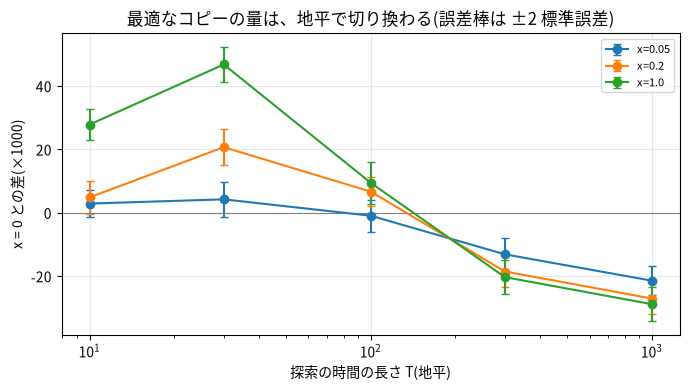

In [24]:
# 地平 T を変え、各 x について「x = 0 との差」(同じ景観・同じ乱数の種で対にした差)の平均と標準誤差を見る(景観 60 個、1 分ほど)
xs_ = [0.05, 0.2, 1.0]
Ts = [10, 30, 100, 300, 1000]
t0 = time.time()
table = {x: [] for x in xs_}
for T in Ts:
    diffs = {x: [] for x in xs_}
    for s in range(60):
        land = NK(64, 4, s)
        base = copy_discard_search(land, 20, T, 0.0, 1000 + s)[0]
        for x in xs_:
            diffs[x].append(copy_discard_search(land, 20, T, x, 1000 + s)[0] - base)
    for x in xs_:
        m = statistics.mean(diffs[x]); se = statistics.stdev(diffs[x]) / math.sqrt(60)
        table[x].append((m, se))
    print(f"T={T:5d}: " + "   ".join(f"x={x}: {table[x][-1][0]*1000:+5.1f} ± {table[x][-1][1]*1000:.1f}" for x in xs_))
print(f"(×1000、± は標準誤差。{time.time() - t0:.0f} 秒)")
fig, ax = plt.subplots(figsize=(7, 4))
for x in xs_:
    ax.errorbar(Ts, [m * 1000 for m, _ in table[x]], yerr=[2 * se * 1000 for _, se in table[x]], marker="o", capsize=3, label=f"x={x}")
ax.axhline(0, color="0.5", lw=.8); ax.set_xscale("log")
ax.set_xlabel("探索の時間の長さ T(地平)"); ax.set_ylabel("x = 0 との差(×1000)")
ax.set_title("最適なコピーの量は、地平で切り換わる(誤差棒は ±2 標準誤差)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

- **短い地平** では、コピーを多く許すほどよい($T \le 100$ で $x = 1$ が最良)。良い世界を早く増やすことで、限られた時間を良い場所に集中できる。
- **長い地平** では、コピーしない方がよい($T \ge 300$ で $x = 0$ が最良)。コピーは世界の多様性を減らし、全員が同じ局所的な山に集まってしまう。各世界が自力で山を登りきれるだけの時間があるなら、独立な世界を多く保つ方が得である。

差は標準誤差の数倍あり、切り換わりははっきりしている。では、どこで切り換わるのか。上の説明が正しければ、切り換わる地平 $T^*$ は「独立な世界(コピーなしの山登り)が局所的な山頂に着くまでの時間」で決まるはずである。各時刻に 1 ビットを無作為に選んで試すので、すべてのビットを一度は試すのに $N \ln N$ 程度の時間がかかる(クーポン収集)。山の大きさ $N$ を変えて確かめる(1 分ほど)。

In [25]:
t0 = time.time()
rows = []
for N in [24, 48, 96]:
    ct = statistics.mean(climb_time(NK(N, 4, s), 7 + s) for s in range(30))
    Ts_ = [int(N * f) for f in (0.5, 1, 2, 4, 8, 16)]
    d = []
    for T in Ts_:
        d.append(statistics.mean(copy_discard_search(NK(N, 4, s), 20, T, 1.0, 1000 + s)[0]
                                 - copy_discard_search(NK(N, 4, s), 20, T, 0.0, 1000 + s)[0] for s in range(30)))
    Tstar = None
    for (T1, d1), (T2, d2) in zip(zip(Ts_, d), zip(Ts_[1:], d[1:])):
        if d1 > 0 >= d2:
            Tstar = math.exp(math.log(T1) + (math.log(T2) - math.log(T1)) * d1 / (d1 - d2)); break
    rows.append((N, ct, Tstar))
    print(f"N={N:3d}: 山頂に着くまでの平均時間 {ct:5.0f}(N ln N = {N * math.log(N):4.0f}),  切り換わる地平 T* ≈ {Tstar:5.0f},  "
          f"T*/山頂までの時間 = {Tstar / ct:.2f}")
print(f"({time.time() - t0:.0f} 秒)")

N= 24: 山頂に着くまでの平均時間    67(N ln N =   76),  切り換わる地平 T* ≈    30,  T*/山頂までの時間 = 0.45


N= 48: 山頂に着くまでの平均時間   204(N ln N =  186),  切り換わる地平 T* ≈    80,  T*/山頂までの時間 = 0.40


N= 96: 山頂に着くまでの平均時間   664(N ln N =  438),  切り換わる地平 T* ≈   250,  T*/山頂までの時間 = 0.38
(47 秒)


切り換わる地平 $T^*$ は、どの大きさでも **山頂に着くまでの時間の約 0.4 倍** だった。地平がそれより短ければ、独立な世界はまだ山の途中にいて、良い世界をコピーして時間を集中する方が得である。地平がそれより長ければ、独立な世界はそれぞれ山頂に着けるので、多くの独立な山頂を持つ方が得である。**どれだけの虚(コピー)を許すべきかは、使える時間と、一つの実実行が自力で定常状態(山頂)に着くまでの時間の比で決まる。**

**既知の話との関係.** 選択(コピー)を強めると集団の多様性が失われ、局所的な山に早く集まってしまう(早すぎる収束)ことは、遺伝的アルゴリズムの分野でよく知られている。Goldberg & Deb(1991)は、選択だけを繰り返したとき最良の個体が集団全体を占めるまでの時間(**takeover time**)で、選択の方式の強さを比べた。二つから良い方を選ぶトーナメント選択なら、takeover time は集団の大きさ $K$ の対数程度である($K = 20$ なら数世代)。ここでの $x = 1$ はその強い選択にあたり、$x$ を小さくすると takeover time は $1/x$ 倍ほどに延びる。最適なコピーの量が地平で切り換わることは、この「選択の速さ」と「各世界が自力で登る速さ」の釣り合いとして理解できる。したがって、地平で切り換わること自体は新しい発見ではない。この稿で付け加えたのは、それを虚実行の木(系譜)の言葉で読むことと、切り換わる地平が山頂に着く時間の約 0.4 倍だったという、この条件での観察である。

系譜の木を見ると、この違いがわかる。最後に残った世界の祖先をさかのぼり、各時刻に何本の系統が生き残っているか(最後の世界たちの共通祖先がいくつあるか)を数える。

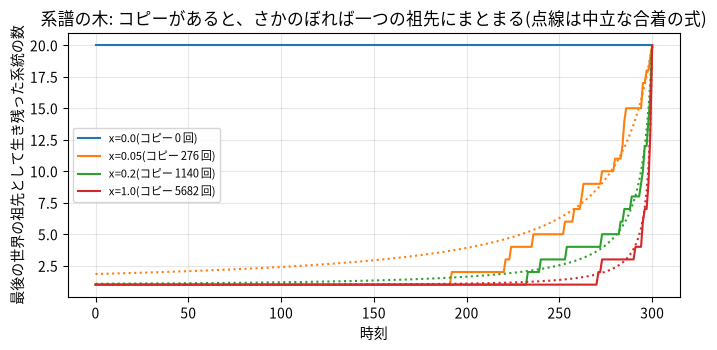

In [26]:
land = NK(64, 4, 0)
fig, ax = plt.subplots(figsize=(7, 3.6))
for x in [0.0, 0.05, 0.2, 1.0]:
    best, hist, copies = copy_discard_search(land, 20, 300, x, 7)
    lin = surviving_lineages(hist, 20)
    line, = ax.plot(range(len(lin)), lin, label=f"x={x}(コピー {copies} 回)")
    if x > 0:
        ax.plot(range(len(lin)), [coalescent_lineages(20, x, 300 - t) for t in range(len(lin))], ls=":", color=line.get_color())
ax.set_xlabel("時刻"); ax.set_ylabel("最後の世界の祖先として生き残った系統の数")
ax.set_title("系譜の木: コピーがあると、さかのぼれば一つの祖先にまとまる(点線は中立な合着の式)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

$x = 0$ では 20 本の系統がすべて最後まで残る(20 本の実実行の束)。点線は、選択がない(中立な)場合の Kingman(1982)の合着の式である。二つの系統が一時刻さかのぼって一つにまとまる確率は約 $p = (2x - x^2)/K$($K$ は世界の数)で、$n$ 本の系統は率 $p\,n(n-1)/2$ で減るので、$t$ 時刻さかのぼったときの系統の数は約 $1/(1 - (1 - 1/K)e^{-pt/2})$ になる。共通祖先までのさかのぼりの長さはおよそ $K/x$ で、**$x$ は系譜の木の深さ(虚実行の木の幹の長さ)の目盛り** になっている。コピーが少しでもあると、最後の世界たちはさかのぼるとすぐに **一つの共通祖先** にまとまり、それより前は一本の幹になる(系譜の木が、細い幹と、最後の短い枝だけになる)。$x$ が大きいほど、その共通祖先は最近の時刻にある(全体が一つの系統に入れ換わるのが速い)。それ以外の系統は、すべて捨てられた葉である。最後に選ばれる「一本の実の道」は、この幹である。

次のセルで、平らな景観(選択が効かない)と NK 景観で、さかのぼった系統の数を合着の式と比べる。

In [27]:
for x in [0.05, 0.2]:
    for name, mk in [("平らな景観", lambda s: Flat(64)), ("NK 景観", lambda s: NK(64, 4, s))]:
        runs = [surviving_lineages(copy_discard_search(mk(s), 20, 400, x, 50 + s)[1], 20) for s in range(40)]
        print(f"x={x} {name:6s}: " + ",  ".join(
            f"{lag} 前 {statistics.mean(r[400 - lag] for r in runs):5.2f}(式 {coalescent_lineages(20, x, lag):4.2f})" for lag in [10, 50, 100, 200, 400]))

x=0.05 平らな景観 : 10 前 13.82(式 13.72),  50 前  6.17(式 6.29),  100 前  3.90(式 3.91),  200 前  2.27(式 2.40),  400 前  1.43(式 1.56)


x=0.05 NK 景観 : 10 前 13.78(式 13.72),  50 前  6.15(式 6.29),  100 前  3.98(式 3.91),  200 前  1.90(式 2.40),  400 前  1.00(式 1.56)
x=0.2 平らな景観 : 10 前  7.28(式 7.59),  50 前  2.27(式 2.54),  100 前  1.52(式 1.63),  200 前  1.15(式 1.19),  400 前  1.00(式 1.03)


x=0.2 NK 景観 : 10 前  7.28(式 7.59),  50 前  2.27(式 2.54),  100 前  1.52(式 1.63),  200 前  1.15(式 1.19),  400 前  1.00(式 1.03)


中立な場合は式とよく合う。NK 景観では、遠い過去ほど式より早くまとまる(選択で良い世界が多くコピーされるので)。$x = 0.2$ では平らな景観と同じ値になった。集団がすぐに同じ世界のコピーばかりになり、適応度の差がなくなるためである。

### 4.3 切り換える予定表

「最適な $x$ が時間の長さで切り換わる」なら、探索の途中で $x$ を切り換えればよいのではないか。いくつかの予定表を試す。

In [28]:
for N, K, T in [(64, 4, 30), (64, 4, 300), (40, 4, 600)]:
    scheds = {"x=0": 0.0, "x=1": 1.0, "x=0.2": 0.2,
              "前半 0 → 後半 1": (lambda t, T=T: 0.0 if t < T // 2 else 1.0),
              "最後の 1 割だけ 1": (lambda t, T=T: 0.0 if t < 0.9 * T else 1.0),
              "前半 1 → 後半 0": (lambda t, T=T: 1.0 if t < T // 2 else 0.0)}
    res = {k: [] for k in scheds}
    for s in range(12):
        land = NK(N, K, s)
        for k, x in scheds.items():
            res[k].append(copy_discard_search(land, 20, T, x, 1000 + s)[0])
    print(f"N={N}, T={T}: " + ",  ".join(f"{k} {statistics.mean(v):.4f}" for k, v in res.items()))

N=64, T=30: x=0 0.6512,  x=1 0.7080,  x=0.2 0.6711,  前半 0 → 後半 1 0.6842,  最後の 1 割だけ 1 0.6538,  前半 1 → 後半 0 0.6874


N=64, T=300: x=0 0.7491,  x=1 0.7380,  x=0.2 0.7350,  前半 0 → 後半 1 0.7440,  最後の 1 割だけ 1 0.7509,  前半 1 → 後半 0 0.7380


N=40, T=600: x=0 0.7667,  x=1 0.7316,  x=0.2 0.7409,  前半 0 → 後半 1 0.7663,  最後の 1 割だけ 1 0.7624,  前半 1 → 後半 0 0.7316


この規模の実験(景観 12 個)では、途中で切り換える予定表は、その時間の長さでの最良の一定値($x = 0$ または $x = 1$)をはっきりとは上回らなかった。「長い探索では、最後の 1 割だけコピーする」はほぼ $x = 0$ と同じで、「短い探索で途中から独立にする」は $x = 1$ に届かない。**どれだけの虚(コピー)を許すべきかは、使える時間の長さ(地平)と、一つの世界が山頂に着くまでの時間の比で決まる** というのが、ここでの主な観察である(§4.2)。地平が短ければ、虚実行の木を細い幹に絞って良い道に集中し、地平が長ければ、多くの独立な実実行の束を保つ。

## §5 JRF の問いへ ―― 主体が切り換わる最適化

JRF は 2025 年 1 月にこうも書いた。

> 拙著『「シミュレーション仏教」の試み』や『宗教学雑考集』を通じて、システムや主体がどんどん切り換わる最適化というのを考えたが定式化できなかった。そこには無限性や独立性や並列性を加味する必要があると感じたのだった。
>
> AI の学習や進化的アルゴリズムは、最適化を「使っている」ことになっているが、しかし、「システムや主体がどんどん切り換わる最適化」を内に含んでいるという点で、実は(数理)最適化を超える「最適化」の例でもあるのではないか?

この稿の結果は、この問いに次のような手がかりを与える。

1. **定常状態と反作用(§1).** 数理最適化は、目的関数の極値(定常状態)を探す。そこでの「反作用」は、不動点の乗数(勾配法なら、目的関数の 2 階微分から決まる収束の速さ)である。乗数の絶対値が 1 の場合、実の範囲に定常状態はなく、振動が続く。その「戻らない定常状態」は虚数の不動点として記述でき、乗数の偏角が振動の速さを決める。JRF の「戻らないことがある種の定常状態になる」は、楕円型の不動点という正確な形を持つ。しかも、実の繰り返しは虚数の不動点のまわりの回転としてちょうど記述され、回転が 1 の冪根でなければ決して戻らない(定理 F′)。逆に $|f'(z)| < 1$ なら傾けても戻る(定理 F″)。
2. **外部接続(§3).** JRF が「サーバーが外部に接続するということが不思議に記述できる」と書いた callCC の goto は、同じ過去に何度も戻る反復で、時間ループの自己無撞着な解は、そこでは終わらない永久ループとして現れる。外部とつながる(他の世界の値を持ち込む)ことは、report1 の言葉では合流であり、report2 の言葉では継続の余分な再開(虚実行)である。
3. **主体が切り換わる最適化(§4).** コピーと破棄による探索では、最適化される「主体」(世界・個体・粒子)そのものが、コピーされ、捨てられ、入れ換わる。数理最適化のように一つの主体が一つの目的関数を登るのではなく、主体の系譜の木を育て、最後に一本の道を選ぶ。そこで調整すべきつまみは目的関数ではなく、**どれだけ主体の入れ換え(コピー)を許すか** という虚の度合い $x$ であり、その最適値は地平の長さで切り換わり、切り換わる地平は一つの主体が自力で定常状態(山頂)に着く時間で決まる。JRF の言う「並列性」は世界を並行に保つこと、「独立性」はコピーしない($x$ が小さい)こと、「無限性」は地平の長さにあたる、と読むことができる。

これは定式化の入り口にすぎない。目的そのものが入れ換わる(多目的最適化で和や最大値をとるのとは違う)ことの定式化、AI の学習(勾配法)と主体の入れ換え(選択)の組み合わせの理論は、今後の課題である。

## §6 まとめ ―― report0〜report3 を通して

### 6.1 この稿のまとめ

- 不動点での微分(乗数)は「傾けたときの反作用」で、絶対値が 1 より小さければ傾けても戻る(定理 F″)。楕円型では乗数の絶対値は 1 で、実の繰り返しは虚数の不動点のまわりの回転として記述され、乗数が 1 の冪根のときに限って元に戻る(定理 F・F′・G、Lean)。
- 線形の振動の複素固有値、発振のバルクハウゼン条件、リング発振器(嘘つきの回路)は、同じ構造の別の姿である。リング発振器は ±1 で書けば線形で、乗数 1 がないことが自己無撞着な状態がないことに当たる(定理 R、Lean)。
- 時間ループを「同じ過去に何度も戻る」反復として実行すると、自己無撞着な解は終わらないループになる。callCC の "stop" はその例である。
- コピーと破棄による探索は虚実行の木を育てて一本の実の道を選ぶ過程で、許すべきコピーの量は地平の長さで切り換わる。切り換わる地平は、独立な世界が山頂に着く時間の約 0.4 倍だった(実験)。系譜の木の深さは中立な合着の式でよく近似でき、コピーの確率 $x$ がその目盛りになる。

### 6.2 四つのレポートを通して

JRF は 2018 年に、ELDE が実際にはありえない実行まで数えていたことに気づき、それを「虚実行」と名付けた。そして「今のままでは「虚実行」そのものに意味を見出すのは難しい」と書いた。四つのレポートを通して、虚実行について次のことがわかった。

| | わかったこと |
|---|---|
| report0 | 虚実行 = 状態をコピーした実行、実実行 = 移動させた実行(定理 1)。局所的には正しく、大域的な線形性だけを破る。ELDE その1 の実行の特徴づけと進行グラフ(定理 2・3)。階層を延ばすと、因果を破る段では実行は自己無撞着なものとしてしか存在しない(定理 4)。時間ループの解に虚数単位が現れる。定理 1〜4 は Lean。 |
| report1 | コピーした世界を合流させる仕組み(トランザクション・MVCC・RCU・git の merge)は「虚実行 + 合流」で、読んだコピーが古くなっていなければ実実行と見分けられない(定理 A)。スナップショット分離の異常は、古いコピーの二段重ね(危険構造)を必ず含む(定理 B)。どちらも Lean。 |
| report2 | 並列プログラムの部品に意味を与えるには、虚の入力が要る(定理 C)。スケジュールを選べる検査者に対しては、各 lock に一つずつの虚の入力が必要かつ十分で、どの一つも省けない(定理 H)。記憶のある相手が見分けるのは「外れたときに一手で潰せる」虚の入力の列だけで(定理 J)、短いプロセスではそれがすべての虚の入力になる(定理 K)。虚の入力の総体を許すと検査の計算量が下がる。継続を余分に再開した回数だけ世界が増え(定理 E)、状態が継続の中にしかない場合は、虚実行は古典論理に、実実行は線形な継続に対応する。複数のプロセスでは、状態の値のコピーだけで、時間ループを除く虚実行がすべて作れる(定理 E′)。 |
| report3 | 実実行が戻らずに回り続けるとき、その定常状態は虚数の不動点にあり、そこでの微分が実実行の周期を決め、1 の冪根でなければ決して戻らない(定理 F・F′・G)。最適化は虚実行の木を育てて一本の実の道を選ぶ過程で、許すべき虚の量は地平と、一つの実実行が定常状態に着く時間の比で決まる。 |

JRF が夢見た「虚数のような数学的な概念拡張」と、このレポート群が着地した「現実の並列処理・データベース・探索の問題」は、次の一点で一致しているように見える。**虚数も虚実行も、局所的な規則はすべて守り、大域的な制約(2 乗は 0 以上、状態は一度しか使わない、未来は読まない)だけを捨てた拡張である。そして、捨てた制約を経由して計算した結果が、最後に「実」に戻ってくるとき、それは正しい現実の答えになる**(JRF『宗教学雑考集』の「虚の理論」)。データベースが虚実行を許して速く動き、観測を実実行と区別できない範囲に抑えるのも、並列プログラムの部品に虚の入力を含む意味を与えて組み立てるのも、振動する実行を虚数の不動点で記述するのも、この形をしている。

一方で、虚数にあった「それがなければ説明できない現象」(Renou ら 2021 の実験)にあたるものは、まだ見つかっていない。それに最も近いのは report2 の結果である。実実行だけの意味は並列合成について閉じず(定理 C)、どの lock の虚の入力も省けない(定理 H (3))。記憶のある相手は、短いプロセスについてはすべての虚の入力を見分ける(定理 K)。これらは「部品に意味を与えるには虚の入力が必要で、その量はちょうどこれだけ」という意味で、虚実行が並列性の記述に必然的な拡張であることを示している。ただし、どれもプロセスの外から観測するモデルの中での結果で、「虚実行がなければ説明できない現実の現象」とまでは言えない。予想 2″ の残り(CS がちょうど状態の数の場合)とあわせて、今後の課題として残る。

### 6.3 今後の課題

1. **メビウス変換以外の時間ループ.** 一般の(非線形の)写像の楕円型不動点と、実の振る舞い(準周期・カオス)との関係。
2. **地平に応じたコピーの予定表.** 切り換わる地平が山頂に着く時間の約 0.4 倍になる理由の理論(この稿では実験による観察にとどまる)。takeover time の理論(Goldberg & Deb 1991 以来)と、山登りの時間の理論を組み合わせれば説明できるはずである。粒子フィルタの系譜の理論(Del Moral 2004)との接続。
3. **勾配と選択の組み合わせ.** 各世界の中の勾配法(実実行の最適化)と、世界のコピーと破棄(虚実行の木)を組み合わせた最適化の定式化。JRF の「主体が切り換わる最適化」の数理。
4. **callCC の意味論.** §3 の反復は再実行による callCC(report2 §8)で書いた。callCC そのものの意味論との一致の形式化は、report2 の今後の課題とした。

## 参考文献

### JRF の文献

- JRF《Exhaustive Lock Dependency Emulator その１ 並列処理の総当り》JRF のソフトウェア Tips, 2011-06-20(追記 2018-04-06)。 http://jrf.cocolog-nifty.com/software/2011/06/post-1.html
- JRF《Haskell の callCC で goto を作る》同, 2011-01-20。 http://jrf.cocolog-nifty.com/software/2011/01/post-2.html
- JRF「ひとこと」[cocolog:95231673] 2025-01-12(Attention 機構と最適化の拡張、微分と反作用、戻らないことがある種の定常状態になる、システムや主体がどんどん切り換わる最適化)。
- JRF『宗教学雑考集 易理・始源論・神義論』第 1.0 版, 2025-03-11(「虚数と超ひも理論」の節)。
- JRF & Claude Opus 5.5『虚実行論』(report0)、『虚実行と合流』(report1)、『虚実行があるからこそ解ける問題』(report2)。

### 力学系・振動

- T. Needham, *Visual Complex Analysis*, Clarendon Press, Oxford, 1997(メビウス変換の分類と乗数)。
- H. Barkhausen, *Lehrbuch der Elektronen-Röhren und ihrer technischen Anwendungen*, Bd. 3, S. Hirzel, Leipzig, 1935(発振条件)。

### 時間ループ

- D. Deutsch, "Quantum mechanics near closed timelike lines", *Physical Review D* 44, 3197, 1991.
- S. Lloyd, L. Maccone, R. Garcia-Patron, V. Giovannetti, Y. Shikano, "Quantum mechanics of time travel through post-selected teleportation", *Physical Review D* 84, 025007, 2011.

### 探索

- J. H. Holland, *Adaptation in Natural and Artificial Systems*, University of Michigan Press, Ann Arbor, 1975.
- B. T. Lowerre, *The HARPY Speech Recognition System*, PhD thesis, Carnegie Mellon University, 1976(ビームサーチ)。
- S. Kauffman, S. Levin, "Towards a general theory of adaptive walks on rugged landscapes", *Journal of Theoretical Biology* 128(1), 11–45, 1987(NK 景観)。
- N. J. Gordon, D. J. Salmond, A. F. M. Smith, "Novel approach to nonlinear/non-Gaussian Bayesian state estimation", *IEE Proceedings F* 140(2), 107–113, 1993(粒子フィルタ)。
- D. E. Goldberg, K. Deb, "A comparative analysis of selection schemes used in genetic algorithms", in G. J. E. Rawlins (ed.), *Foundations of Genetic Algorithms*, Morgan Kaufmann, 1991(takeover time)。
- P. Del Moral, *Feynman–Kac Formulae: Genealogical and Interacting Particle Systems with Applications*, Springer, New York, 2004(粒子の系譜の木)。
- J. F. C. Kingman, "The coalescent", *Stochastic Processes and their Applications* 13(3), 235–248, 1982(合着)。

### その他

- M.-O. Renou ら, "Quantum theory based on real numbers can be experimentally falsified", *Nature* 600, 2021.
- L. de Moura, S. Ullrich, "The Lean 4 theorem prover and programming language", *CADE-28*, 2021. / The mathlib Community, "The Lean mathematical library", *CPP* 2020.

### 謝辞と注意

本稿の整理(JRF の「微分と反作用」「戻らない定常状態」を不動点の乗数と楕円型不動点として読むこと、コピーと破棄の探索を虚実行の木として読むこと、§5 の対応づけ)は、Claude Opus 5.5 が JRF の日記と記事をもとに組み立てた解釈である。定理 F・F′・F″・G・R は Lean 4 + Mathlib で証明したが、どれもメビウス変換と線形写像の古典的な事実である。§4 の探索の実験は景観 60 個(切り換わる地平の実験は各 30 個)で、差は標準誤差の数倍あるが、NK 景観・世界 20 個という条件での観察である。「切り換わる地平が山頂に着く時間の約 0.4 倍」は理論ではなく実験の観察である。文献は照合した(記録は refs_BIBLIO.md)。

## 付録: Lean による一括検証

ここまでの `%%writefile` セルで `test.lean` が出来上がっている。最後に、使った公理を表示する行を足し、Lean 4(v4.34.1)+ Mathlib(v4.34.1)をそろえてまとめて検証する。

* **Colab**: elan をインストールし、`imagexec_lean/` に Mathlib を依存に持つ Lake プロジェクトを作る。`lake exe cache get` でビルド済みの .olean を取得する(初回は数分)。
* **ローカル**: カレントディレクトリかその親に、すでに Mathlib 入りの `lakefile.lean` があれば、それをそのまま使う。

エラーがなく、`#print axioms` が標準の公理(`propext`, `Classical.choice`, `Quot.sound`)だけを挙げれば、証明は通っている。

In [29]:
%%writefile -a test.lean
#print axioms ImagExec.R3.mob_hasDerivAt
#print axioms ImagExec.R3.multiplier_at_fixed
#print axioms ImagExec.R3.period
#print axioms ImagExec.R3.rot_multiplier
#print axioms ImagExec.R3.elliptic_unit
#print axioms ImagExec.R3.elliptic_return
#print axioms ImagExec.R3.converge
#print axioms ImagExec.R3.ring_N
#print axioms ImagExec.R3.ring_2N
#print axioms ImagExec.R3.ring_no_fixed


Appending to test.lean


In [30]:
%%bash
set -e
export PATH="$HOME/.elan/bin:$PATH"
if [ -f lakefile.lean ] && grep -q mathlib lakefile.lean; then
  echo "using the existing Lake project in the current directory"
  echo "." > .leandir
elif [ -f ../lakefile.lean ] && grep -q mathlib ../lakefile.lean; then
  echo "using the existing Lake project in the parent directory"
  echo ".." > .leandir
else
  if ! command -v lake >/dev/null 2>&1; then
    curl -sSfL https://raw.githubusercontent.com/leanprover/elan/master/elan-init.sh \
      | sh -s -- -y --default-toolchain none
  fi
  mkdir -p imagexec_lean && cd imagexec_lean
  echo 'leanprover/lean4:v4.34.1' > lean-toolchain
  cat > lakefile.lean <<'EOF'
import Lake
open Lake DSL

package imagexec_lean

require mathlib from git
  "https://github.com/leanprover-community/mathlib4.git" @ "v4.34.1"
EOF
  lake update 2>&1 | tail -3
  lake exe cache get 2>&1 | tail -3
  cd ..
  echo "imagexec_lean" > .leandir
fi

using the existing Lake project in the parent directory


In [31]:
%%bash
export PATH="$HOME/.elan/bin:$PATH"
LEANDIR=$(cat .leandir)
FILE=$(pwd)/test.lean
cd "$LEANDIR"
time lake env lean "$FILE" && echo "=== test.lean: all theorems checked ==="


'ImagExec.R3.mob_hasDerivAt' depends on axioms: [propext, Classical.choice, Quot.sound]
'ImagExec.R3

.multiplier_at_fixed' depends on axioms: [propext, Classical.choice, Quot.sound]
'ImagExec.R3.period

' depends on axioms: [propext, Classical.choice, Quot.sound]
'ImagExec.R3.rot_multiplier' depends on

 axioms: [propext, Classical.choice, Quot.sound]
'ImagExec.R3.elliptic_unit' depends on axioms: [pro

pext, Classical.choice, Quot.sound]
'ImagExec.R3.elliptic_return' depends on axioms: [propext, Class

ical.choice, Quot.sound]
'ImagExec.R3.converge' depends on axioms: [propext, Classical.choice, Quot.

sound]
'ImagExec.R3.ring_N' depends on axioms: [propext, Quot.sound]
'ImagExec.R3.ring_2N' depends o

n axioms: [propext, Quot.sound]
'ImagExec.R3.ring_no_fixed' depends on axioms: [propext, Classical.c

hoice, Quot.sound]



real	0m3.019s
user	0m3.033s
sys	0m0.989s


=== test.lean: all theorems checked ===
